# 2. Analysis: what's changed at the Austin Animal Center since 2014?

Austin is known as the largest "no-kill" city in the US. The city's goal is to save at least 95% of animals. With 11 years of cleaned and linked data, I looked at five questions:

1. How has intake volume changed?
2. Are animals staying longer, and is the shelter keeping up?
3. Is the live release rate holding?
4. Which animals wait the longest to be adopted?
5. How many adoptions come back, and when?

I focus on **dogs and cats** (94% of intakes). Wildlife and other animals follow a different process, so they would skew the rates. 2013 and 2025 are partial years and are left out of yearly trends.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

ACCENT, ACCENT2, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#b4b2a9", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10.5,
    "legend.frameon": False,
})
def save(name):
    plt.tight_layout()
    plt.savefig("../images/" + name, bbox_inches="tight", dpi=150)
    plt.show()

s = pd.read_parquet("../data/processed/stays.parquet")
s["year"] = s["intake_at"].dt.year
dc = s[s["animal_type"].isin(["Dog", "Cat"])].copy()
full_years = dc[dc["year"].between(2014, 2024)]
done = full_years[full_years["has_outcome"]]
COLORS = {"Dog": ACCENT, "Cat": ACCENT2}
print(f"Dog and cat stays: {len(dc):,} of {len(s):,} ({len(dc)/len(s):.0%})")

Dog and cat stays: 163,901 of 173,776 (94%)


## 2.1 Intake volume

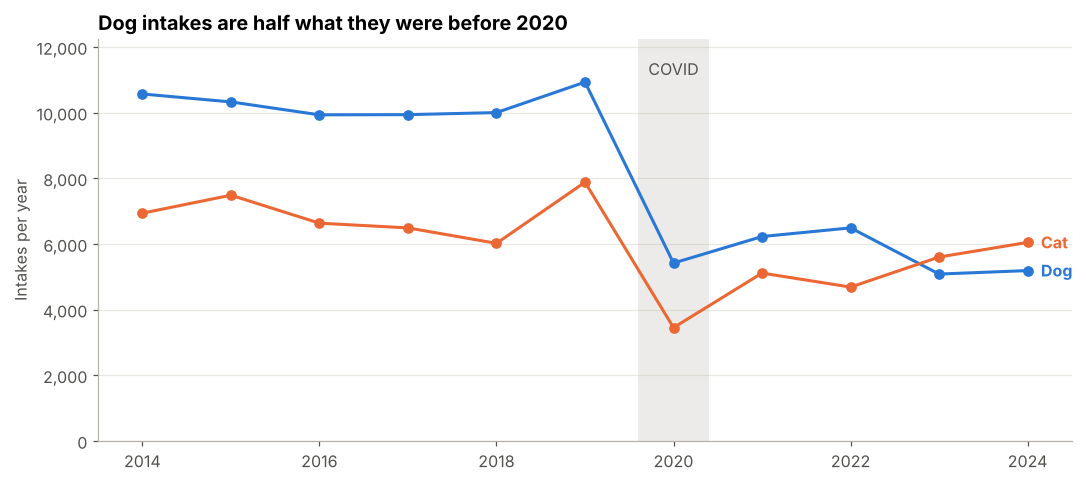

animal_type,Cat,Dog
year,,
2014,6937,10567
2015,7484,10326
2016,6632,9932
2017,6488,9938
2018,6018,10001
2019,7880,10929
2020,3450,5417
2021,5112,6225
2022,4685,6489


In [2]:
vol = full_years.pivot_table(index="year", columns="animal_type", values="animal_id", aggfunc="count")
fig, ax = plt.subplots()
for t in ["Dog", "Cat"]:
    ax.plot(vol.index, vol[t], color=COLORS[t], lw=2, marker="o", ms=6)
    ax.text(vol.index[-1] + 0.15, vol[t].iloc[-1], t, color=COLORS[t], va="center", fontweight="bold")
ax.axvspan(2019.6, 2020.4, color=GRAY, alpha=0.25, lw=0)
ax.text(2020, vol.values.max() * 1.02, "COVID", ha="center", color=MUTED)
ax.set_ylim(0, vol.values.max() * 1.12)
ax.set_title("Dog intakes are half what they were before 2020")
ax.set_ylabel("Intakes per year")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)
save("02_intakes_by_year.png")
vol

Intakes fell sharply in 2020 and never came back for dogs: about 10,000 a year before COVID, about 5,100 in 2023 and 2024. Cats have mostly recovered. So in 2023, for the first time, the shelter took in more cats than dogs.

Fewer intakes sounds like good news, but it should be read next to the next chart.

## 2.2 Length of stay

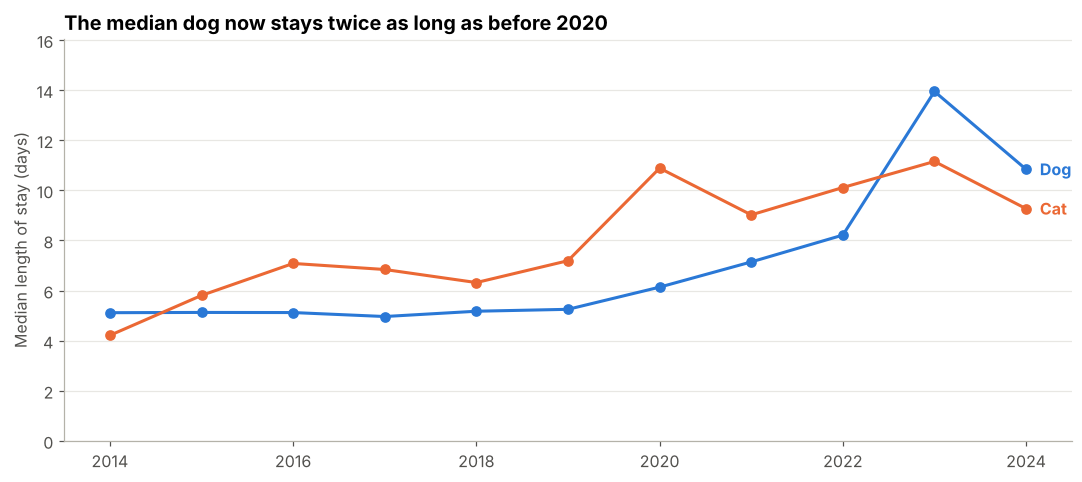

animal_type,Cat,Dog
year,,
2014,4.2,5.1
2015,5.8,5.1
2016,7.1,5.1
2017,6.8,5.0
2018,6.3,5.2
2019,7.2,5.3
2020,10.9,6.1
2021,9.0,7.1
2022,10.1,8.2


In [3]:
los = done.pivot_table(index="year", columns="animal_type", values="length_of_stay_days", aggfunc="median")
fig, ax = plt.subplots()
for t in ["Dog", "Cat"]:
    ax.plot(los.index, los[t], color=COLORS[t], lw=2, marker="o", ms=6)
    ax.text(los.index[-1] + 0.15, los[t].iloc[-1], t, color=COLORS[t], va="center", fontweight="bold")
ax.set_ylim(0, los.values.max() * 1.15)
ax.set_title("The median dog now stays twice as long as before 2020")
ax.set_ylabel("Median length of stay (days)")
ax.grid(axis="x", visible=False)
save("03_length_of_stay_by_year.png")
los.round(1)

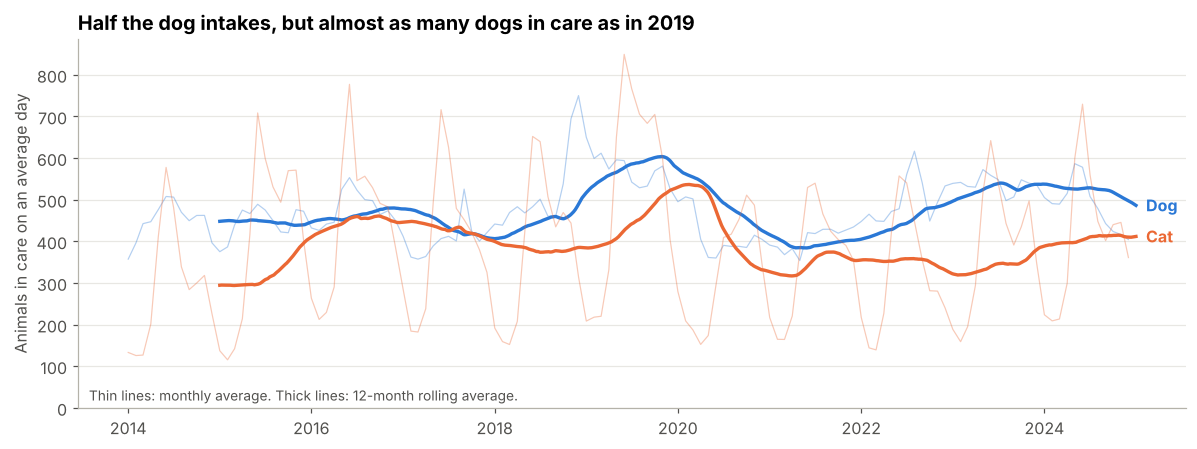

type,Cat,Dog
date,,
2014,294.0,448.0
2015,408.0,446.0
2016,445.0,478.0
2017,399.0,406.0
2018,383.0,516.0
2019,528.0,575.0
2020,327.0,417.0
2021,354.0,405.0
2022,321.0,496.0


In [4]:
# Animals in care on each day = intakes so far minus outcomes so far.
# Stays with no recorded outcome are left out, otherwise they'd pile up as "in care" forever.
linked = dc[dc["has_outcome"]]
events = pd.concat([
    pd.DataFrame({"date": linked["intake_at"].dt.floor("D"), "type": linked["animal_type"], "chg": 1}),
    pd.DataFrame({"date": linked["outcome_at"].dt.floor("D"), "type": linked["animal_type"], "chg": -1}),
])
census = (events.groupby(["date", "type"])["chg"].sum().unstack(fill_value=0)
          .asfreq("D", fill_value=0).cumsum())
census = census.loc["2014-01-01":"2024-12-31"]
monthly_census = census.resample("MS").mean()
rolling = census.rolling(365).mean().loc["2015-01-01":]   # 12-month average removes kitten-season swings

fig, ax = plt.subplots(figsize=(11, 4.2))
for t in ["Dog", "Cat"]:
    ax.plot(monthly_census.index, monthly_census[t], color=COLORS[t], lw=0.8, alpha=0.35)
    ax.plot(rolling.index, rolling[t], color=COLORS[t], lw=2.2)
    ax.text(rolling.index[-1] + pd.Timedelta(days=40), rolling[t].iloc[-1], t, color=COLORS[t], va="center", fontweight="bold")
ax.text(0.01, 0.02, "Thin lines: monthly average. Thick lines: 12-month rolling average.", transform=ax.transAxes, color=MUTED, fontsize=9)
ax.set_ylim(0)
ax.set_title("Half the dog intakes, but almost as many dogs in care as in 2019")
ax.set_ylabel("Animals in care on an average day")
ax.grid(axis="x", visible=False)
save("04_animals_in_care.png")
monthly_census.groupby(monthly_census.index.year).mean().round(0)

This is the most important finding. Dogs used to leave in about 5 days. In 2023 the median dog stayed **14 days**. Because each dog stays so much longer, the shelter held about 540 dogs on an average day in 2023, close to the 575 of 2019 and more than any year from 2014 to 2018, even though half as many dogs came in. Population in care is what drives kennel space, staff time and cost, so on the measure that matters, the shelter isn't any less busy.

## 2.3 Live release rate

Live release rate = live outcomes (adoption, return to owner, transfer) ÷ all final outcomes. Missing, lost and stolen animals are excluded.

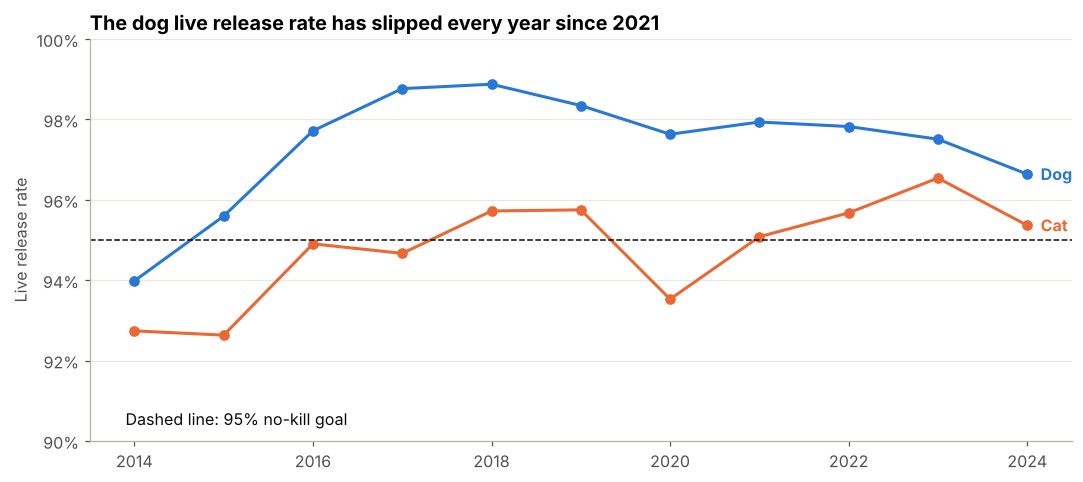

animal_type,Cat,Dog
year,,
2014,92.7,94.0
2015,92.6,95.6
2016,94.9,97.7
2017,94.7,98.8
2018,95.7,98.9
2019,95.7,98.3
2020,93.5,97.6
2021,95.1,97.9
2022,95.7,97.8


In [5]:
final = done[~done["outcome_type"].isin(["Missing", "Lost", "Stolen", "Unknown"])]
lrr = final.pivot_table(index="year", columns="animal_type", values="is_live_outcome", aggfunc="mean") * 100
fig, ax = plt.subplots()
for t in ["Dog", "Cat"]:
    ax.plot(lrr.index, lrr[t], color=COLORS[t], lw=2, marker="o", ms=6)
    ax.text(lrr.index[-1] + 0.15, lrr[t].iloc[-1], t, color=COLORS[t], va="center", fontweight="bold")
ax.axhline(95, color=INK, ls="--", lw=1)
ax.text(2013.9, 90.3, "Dashed line: 95% no-kill goal", color=INK, va="bottom")
ax.set_ylim(90, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("The dog live release rate has slipped every year since 2021")
ax.set_ylabel("Live release rate")
ax.grid(axis="x", visible=False)
save("05_live_release_rate.png")
lrr.round(1)

Both species are above the 95% goal, but the trend for dogs is heading the wrong way: 98.9% in 2018, 96.6% in 2024. That lines up with the longer stays above. When dogs stay longer, kennels fill up and the shelter has less room to work with.

## 2.4 Who waits longest to be adopted?

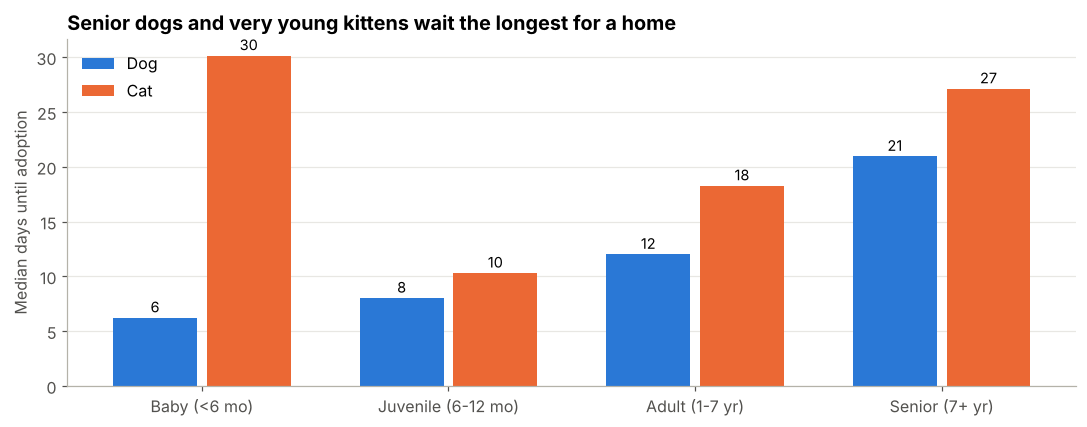

animal_type,Cat,Dog
age_group,,
Baby (<6 mo),30.1,6.2
Juvenile (6-12 mo),10.3,8.0
Adult (1-7 yr),18.3,12.0
Senior (7+ yr),27.1,21.0


In [6]:
adopted = done[done["outcome_type"] == "Adoption"].copy()
adopted["pit_bull"] = adopted["breed"].str.contains("Pit Bull")
order = ["Baby (<6 mo)", "Juvenile (6-12 mo)", "Adult (1-7 yr)", "Senior (7+ yr)"]
by_age = adopted[adopted["age_group"].isin(order)].pivot_table(index="age_group", columns="animal_type",
                                                                values="length_of_stay_days", aggfunc="median").reindex(order)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order)); w = 0.38
for k, t in enumerate(["Dog", "Cat"]):
    bars = ax.bar(x + (k - 0.5) * w, by_age[t], width=w - 0.04, color=COLORS[t], label=t)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{b.get_height():.0f}", ha="center", fontsize=9.5)
ax.set_xticks(x, order)
ax.set_title("Senior dogs and very young kittens wait the longest for a home")
ax.set_ylabel("Median days until adoption")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save("06_wait_by_age.png")
by_age.round(1)

Kittens wait long for a practical reason: they can't be adopted until they're old enough to be spayed or neutered, so they usually spend weeks in foster first. For dogs, age is the real driver: a senior dog waits more than three times as long as a puppy.

Breed and color are the other two things adopters are known to react to. I tested both.

In [7]:
dogs = adopted[adopted["animal_type"] == "Dog"]
cats = adopted[adopted["animal_type"] == "Cat"]
rows = []
for label, d, flag in [("Dogs: pit bull type vs other", dogs, "pit_bull"),
                       ("Dogs: black vs other colors", dogs, "is_black"),
                       ("Cats: black vs other colors", cats, "is_black")]:
    a, b = d.loc[d[flag], "length_of_stay_days"], d.loc[~d[flag], "length_of_stay_days"]
    p = stats.mannwhitneyu(a, b).pvalue
    rows.append((label, len(a), round(a.median(), 1), round(b.median(), 1), round(a.median() / b.median(), 2), p))
tests = pd.DataFrame(rows, columns=["comparison", "n (group)", "median days (group)", "median days (others)", "ratio", "p-value"])
tests["p-value"] = tests["p-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
tests

,comparison,n (group),median days (group),median days (others),ratio,p-value
0,Dogs: pit bull type vs other,7143,29.0,8.1,3.58,< 0.001
1,Dogs: black vs other colors,12280,9.1,9.3,0.99,0.069
2,Cats: black vs other colors,7340,30.2,25.1,1.20,< 0.001


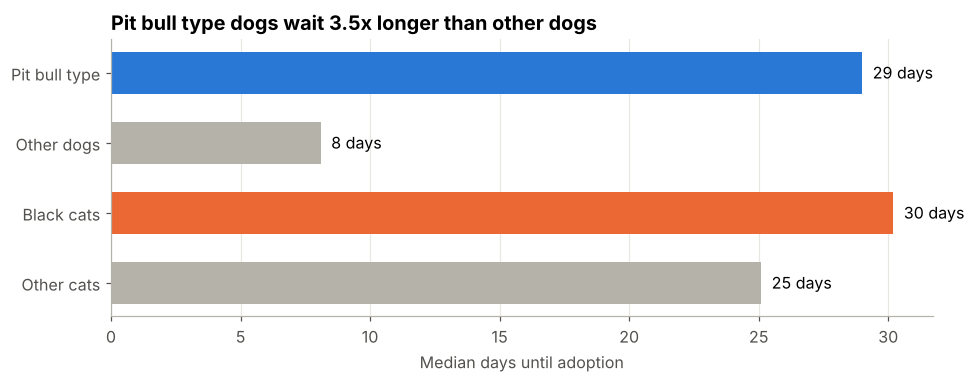

In [8]:
labels = ["Pit bull type", "Other dogs", "Black cats", "Other cats"]
vals = [tests.iloc[0, 2], tests.iloc[0, 3], tests.iloc[2, 2], tests.iloc[2, 3]]
cols = [ACCENT, GRAY, ACCENT2, GRAY]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(labels[::-1], vals[::-1], color=cols[::-1], height=0.6)
for y, v in enumerate(vals[::-1]):
    ax.text(v + 0.4, y, f"{v:.0f} days", va="center")
ax.set_title("Pit bull type dogs wait 3.5x longer than other dogs")
ax.set_xlabel("Median days until adoption")
ax.grid(axis="y", visible=False)
save("07_breed_color.png")

- **Pit bull type dogs wait about 29 days, compared with 8 for other dogs.** It's the biggest single gap in the data, and with 7,400 adoptions it's not noise.
- **Black cats wait about 5 days longer** than other cats (statistically significant), which matches the well-known "black cat" bias.
- **Black dogs don't wait longer.** The "black dog syndrome" people talk about doesn't show up here.

These are differences, not causes. Pit bull type dogs are also more often adult males, for example. But for deciding where to focus adoption promotion, the gap is what counts.

## 2.5 Seasonality: kitten season

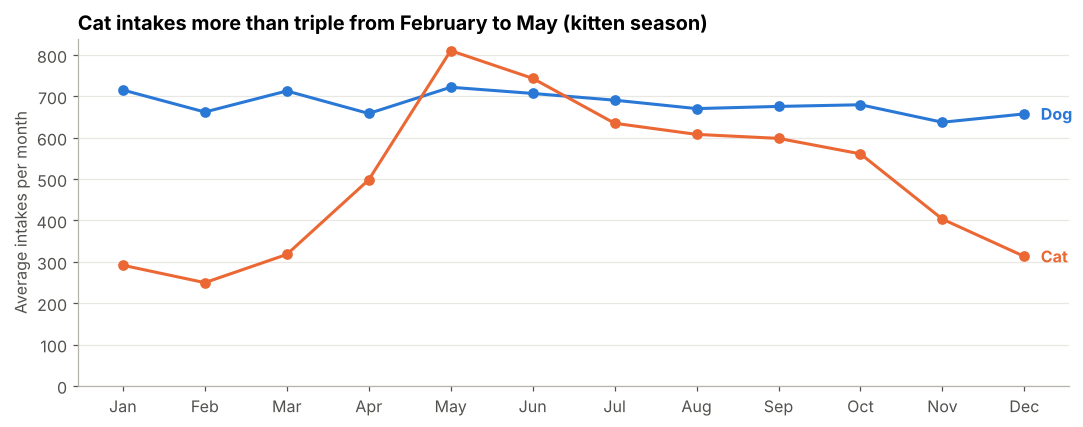

np.float64(3.25)

In [9]:
season = full_years.groupby([full_years["intake_at"].dt.month, "animal_type"]).size().unstack() / full_years["year"].nunique()
fig, ax = plt.subplots(figsize=(10, 4))
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
for t in ["Dog", "Cat"]:
    ax.plot(months, season[t], color=COLORS[t], lw=2, marker="o", ms=6)
    ax.text(11.2, season[t].iloc[-1], t, color=COLORS[t], va="center", fontweight="bold")
ax.set_ylim(0)
ax.set_title("Cat intakes more than triple from February to May (kitten season)")
ax.set_ylabel("Average intakes per month")
ax.grid(axis="x", visible=False)
save("08_seasonality.png")
(season["Cat"].max() / season["Cat"].min()).round(2)

Dog intakes are fairly steady all year. Cat intakes peak in May and June, when litters of kittens arrive, many of them too young to be adopted. That's when foster homes are needed most, and it's predictable months in advance.

## 2.6 Returns after adoption

In [10]:
adopt_all = dc[dc["outcome_type"] == "Adoption"]
returns = dc[dc["is_return_after_adoption"]]
gap = returns["days_since_last_outcome"]
window = adopt_all["outcome_at"] <= adopt_all["outcome_at"].max() - pd.Timedelta(days=180)
eligible = adopt_all[window]
ret_keys = set(zip(returns["animal_id"], returns["stay_number"] - 1))
eligible_returned_180 = sum((a, n) in ret_keys for a, n in zip(eligible["animal_id"], eligible["stay_number"]))
ret_map = returns.set_index(["animal_id", "stay_number"])["days_since_last_outcome"]
ret_within = sum(1 for a, n in zip(eligible["animal_id"], eligible["stay_number"])
                 if (a, n + 1) in ret_map.index and ret_map[(a, n + 1)] <= 180)
print(f"Adoptions with at least 180 days of follow-up: {len(eligible):,}")
print(f"Returned within 180 days: {ret_within:,} ({ret_within / len(eligible):.1%})")
print(f"Of all returns, share within 30 days: {(gap <= 30).mean():.0%}")

Adoptions with at least 180 days of follow-up: 79,360
Returned within 180 days: 7,512 (9.5%)
Of all returns, share within 30 days: 51%


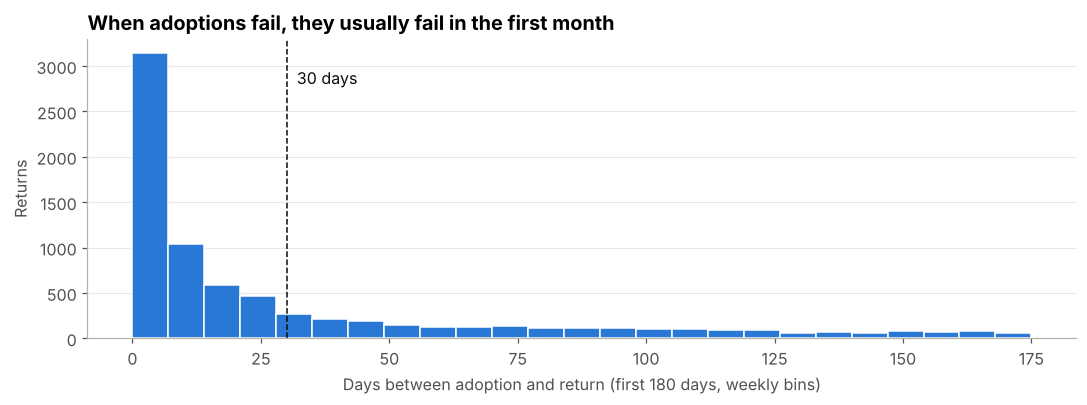

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(0, 181, 7)
ax.hist(gap[gap <= 180], bins=bins, color=ACCENT, edgecolor="white")
ax.axvline(30, color=INK, ls="--", lw=1)
ax.text(32, ax.get_ylim()[1] * 0.85, "30 days", color=INK)
ax.set_title("When adoptions fail, they usually fail in the first month")
ax.set_xlabel("Days between adoption and return (first 180 days, weekly bins)")
ax.set_ylabel("Returns")
ax.grid(axis="x", visible=False)
save("09_returns.png")

About 1 in 10 adoptions (9.5%) comes back to the shelter within six months, and half of all returns happen in the first 30 days. So the first month is when support matters most.

## 3. Recommendations

1. **Track animals in care, not just intakes.** Intakes fell by half for dogs, but the number of dogs in care barely moved. A daily census and median length of stay should sit next to intake counts in every report. That's the first page of my Power BI dashboard.
2. **Put adoption promotion behind the dogs who wait longest.** Pit bull type and senior dogs wait 3 to 4 times longer than other dogs. Reduced fees, "staff pick" profiles and foster-to-adopt programs for these groups would free the most kennel days.
3. **Plan for kitten season in February, not May.** Cat intakes more than triple each spring, and most of those kittens need foster care before adoption. Recruiting fosters ahead of time is predictable and cheap.
4. **Follow up with adopters in the first 30 days.** Half of all returns happen in the first month. A check-in call or behavior helpline in that window targets exactly when adoptions fail.

## 4. Limitations
- An outcome is linked to the right intake using timestamps. 0.9% of stays have no outcome (mostly animals still in care at export) and are excluded from rates.
- "Pit bull type" and color come from shelter intake labels, which are visual guesses and can be inconsistent.
- Differences in wait time are associations, not causes. Age, sex, health and size overlap with breed.
- "Returns" only counts animals that came back to this shelter. Animals rehomed privately don't show up.